# Faithful vs. differentiable screening

The screen is the heart of iBART: after every round of operators it decides
which descriptors survive. `jax-ibart` has two interchangeable screens:

- **`bart`**: the BART-G.SE permutation test (Bleich et al. 2014), run with
  `bartz`. Fit a Bayesian additive regression tree model, record how often each
  feature is used in a split, then refit many times with `y` permuted to learn
  how often each feature is used *by chance*. Keep features used clearly more
  often than chance. This is what the R iBART package does.
- **`diff`**: a gated neural network. Each feature passes through a stochastic
  hard-concrete gate (Louizos et al. 2018) with an L0 penalty, trained by
  gradient descent. Keep features whose gate ends up open.

We test both on the Friedman function, where `y` depends on `x0` and `x1` only
and six other features are noise.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax
from jax_ibart.selection import BartGSESelector, DiffSelector

rng = np.random.default_rng(0)
X = rng.uniform(0, 1, size=(120, 8))
y = 10 * np.sin(np.pi * X[:, 0] * X[:, 1]) + rng.normal(0, 0.5, 120)

In [2]:
diff = DiffSelector(steps=1500)
t0 = time.perf_counter()
diff_keep = np.asarray(diff.select(X, y, key=jax.random.PRNGKey(0)))
t_diff = time.perf_counter() - t0

bart = BartGSESelector(n_perm=15, n_tree=40, n_draw=300, n_burn=300)
t0 = time.perf_counter()
bart_keep = np.asarray(bart.select(X, y, key=jax.random.PRNGKey(0)))
t_bart = time.perf_counter() - t0

print(f"diff keeps {np.where(diff_keep)[0].tolist()}  ({t_diff:.1f} s)")
print(f"bart keeps {np.where(bart_keep)[0].tolist()}  ({t_bart:.1f} s)")
print("truth      [0, 1]")

diff keeps [0, 1]  (1.2 s)
bart keeps [0, 1]  (4.0 s)
truth      [0, 1]


## What each screen sees

Both selectors expose their evidence after `select`: `DiffSelector.importance_`
holds the gate-open probabilities, and `BartGSESelector.diagnostics_` holds the
observed split proportions (`q_obs`), the permutation null draws and the
per-feature threshold.

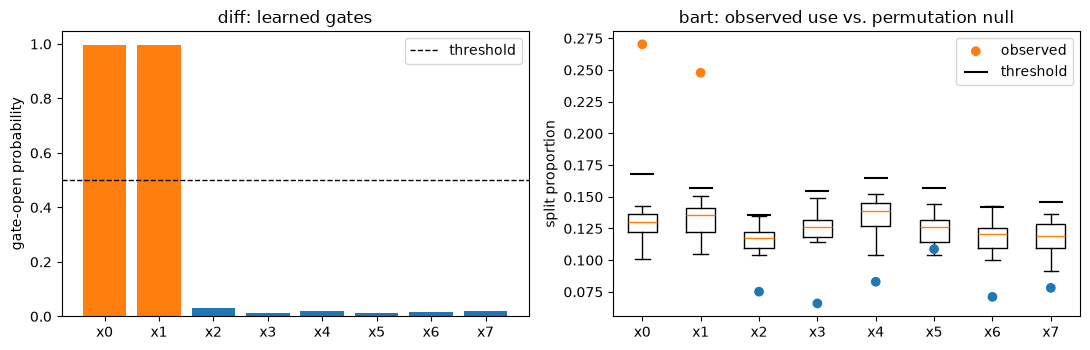

In [3]:
feat = [f"x{j}" for j in range(X.shape[1])]
xs = np.arange(len(feat))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

imp = np.asarray(diff.importance_)
axes[0].bar(xs, imp, color=["C1" if k else "C0" for k in diff_keep])
axes[0].axhline(diff.threshold, color="k", ls="--", lw=1, label="threshold")
axes[0].set_xticks(xs, feat)
axes[0].set_ylabel("gate-open probability")
axes[0].set_title("diff: learned gates")
axes[0].legend()

dg = bart.diagnostics_
null = np.asarray(dg["null"])
axes[1].boxplot([null[:, j] for j in xs], positions=xs, widths=0.5,
                showfliers=False)
axes[1].scatter(xs, dg["q_obs"], color=["C1" if k else "C0" for k in bart_keep],
                zorder=3, label="observed")
axes[1].scatter(xs, dg["threshold"], marker="_", s=300, color="k",
                zorder=3, label="threshold")
axes[1].set_xticks(xs, feat)
axes[1].set_ylabel("split proportion")
axes[1].set_title("bart: observed use vs. permutation null")
axes[1].legend()
fig.tight_layout()
plt.show()

Orange marks a kept feature. The gate model drives the noise gates to zero. BART
uses `x0` and `x1` in about twice as many splits as the permutation null would
explain; the other features sit inside their null distributions.

## When to use which

| | `bart` (faithful) | `diff` (differentiable) |
|---|---|---|
| Fidelity | high; matches R iBART | lower on hard, high-dimensional screens |
| Speed | seconds to minutes (CPU) | seconds |
| Differentiable | no (discrete MCMC) | yes, end to end |
| Use for | final and validated results | fast exploration, gradient-based work |

On the real catalysis screen (see the [catalysis notebook](02_catalysis.ipynb)
and [the benchmark](../benchmark.md)), `diff` is much faster but finds a less
accurate model.